# Mon propre modèle d'IA : reconnaître de quoi parle une page de rapport ITIE

**Le problème :** un rapport ITIE fait plus de 400 pages. Pour trouver où sont les paiements, la production, la gouvernance…, il faut tout feuilleter. Au notebook 07, on a trouvé le tableau des paiements grâce à son titre exact. Mais le titre change d'un pays à l'autre et d'une année à l'autre.

**L'idée :** entraîner un modèle qui lit le texte d'une page et dit de quel **thème** elle parle, sans chercher de titre.

**Les étiquettes « gratuites » :** pour apprendre, un modèle a besoin d'exemples déjà classés. Plutôt que d'annoter des centaines de pages à la main, on utilise le **sommaire** du rapport : il dit que en 2022, la section 4.1 (secteur minier) va de la page 22 à la page 103, la section 4.2 (hydrocarbures) de la page 104 à la page 112, etc. Le fichier `data/itie_themes.csv` regroupe les sections en **7 thèmes** :

| Thème | Sections | Ce qu'on y trouve |
|---|---|---|
| synthese | 1, 2, 3 | présentation de l'ITIE, résumé, méthode |
| secteur_minier | 4, 4.1 | gisements, lois, titres miniers, production, exportations |
| hydrocarbures | 4.2 | pétrole |
| revenus | 4.3, 4.4, 7 | collecte des revenus, poids dans l'économie, budget |
| gouvernance | 4.5 à 4.11 | propriété réelle, environnement, corruption, genre |
| rapprochement | 5, 6 | périmètre et rapprochement des paiements |
| recommandations | 8 | recommandations et leur suivi |

**Le test honnête :** on entraîne sur le rapport **2022** et on teste sur le rapport **2023**, que le modèle n'a jamais vu. C'est le même principe qu'à l'étape 5 : on juge un modèle sur des données qu'il n'a pas apprises.

**Avant de lancer ce notebook :** `py -3.13 src/preparer_pages_itie.py` (quelques minutes), qui crée `data/itie/pages_etiquetees.csv`.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.naive_bayes import MultinomialNB

from src.classifieur_pages import creer_modele, mots_les_plus_utiles, pages_les_plus_probables
from src.graphiques import graphique_matrice_confusion

## 1. Les données : une ligne par page

In [2]:
pages = pd.read_csv("../data/itie/pages_etiquetees.csv")
pd.crosstab(pages["theme"], pages["annee"], margins=True)

annee,2022,2023,All
theme,,,
gouvernance,21,25,46
hydrocarbures,9,8,17
rapprochement,29,25,54
recommandations,19,13,32
revenus,18,21,39
secteur_minier,83,74,157
synthese,13,12,25
All,192,178,370


**Constat :** 192 pages en 2022, 178 en 2023. Les thèmes sont très déséquilibrés : le secteur minier occupe à lui seul plus de 40 % des pages, les hydrocarbures moins de 5 %. Un modèle paresseux pourrait répondre « secteur minier » à chaque fois. C'est pour cela qu'on lui demande de donner autant d'importance aux petits thèmes (`class_weight="balanced"`).

## 2. Entraîner sur 2022, tester sur 2023

In [3]:
entrainement = pages[pages["annee"] == 2022]
test = pages[pages["annee"] == 2023]

modele = creer_modele()
modele.fit(entrainement["texte"], entrainement["theme"])      # le modèle apprend sur 2022
predictions = modele.predict(test["texte"])                   # il devine le thème des pages 2023
print(f"Bonnes réponses sur 2023 : {accuracy_score(test['theme'], predictions):.0%}")

Bonnes réponses sur 2023 : 93%


## 3. Comparaison avec d'autres modèles

In [4]:
modeles = {
    "Répond toujours le thème le plus fréquent": DummyClassifier(strategy="most_frequent"),
    "Naive Bayes (TF-IDF)": creer_modele(MultinomialNB(alpha=0.1)),
    "Régression logistique (TF-IDF)": creer_modele(),
}
scores = {}
for nom, m in modeles.items():
    m.fit(entrainement["texte"], entrainement["theme"])
    scores[nom] = accuracy_score(test["theme"], m.predict(test["texte"]))
pd.Series(scores, name="bonnes réponses sur 2023").map("{:.0%}".format)

Répond toujours le thème le plus fréquent    42%
Naive Bayes (TF-IDF)                         96%
Régression logistique (TF-IDF)               93%
Name: bonnes réponses sur 2023, dtype: str

**Constat :**
- Un « modèle » qui répond toujours *secteur minier* a raison **42 %** du temps : c'est le minimum à battre.
- Les deux vrais modèles font **93 % et 96 %** : plus de deux fois mieux.
- Naive Bayes fait un peu mieux que la régression logistique ici. Avec 178 pages de test, la différence est de 4 pages : ce n'est pas un écart qui permet de dire qu'un modèle est meilleur en général. On garde la régression logistique pour la suite, parce qu'elle donne des **poids par mot** faciles à expliquer (partie 5) et des probabilités plus fiables.

## 4. Où le modèle se trompe-t-il ?

                 precision    recall  f1-score   support

    gouvernance       0.86      1.00      0.93        25
  hydrocarbures       0.80      1.00      0.89         8
  rapprochement       1.00      0.96      0.98        25
recommandations       0.93      1.00      0.96        13
        revenus       0.94      0.76      0.84        21
 secteur_minier       0.96      0.93      0.95        74
       synthese       0.92      0.92      0.92        12

       accuracy                           0.93       178
      macro avg       0.92      0.94      0.92       178
   weighted avg       0.94      0.93      0.93       178



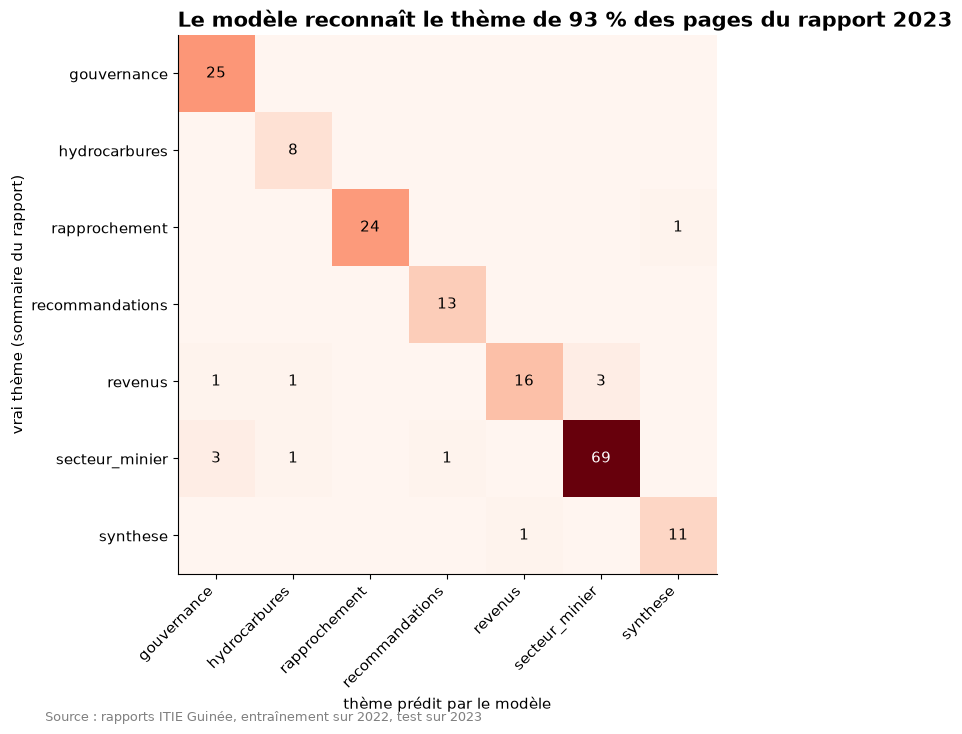

In [5]:
print(classification_report(test["theme"], predictions, zero_division=0))
graphique_matrice_confusion(test["theme"], predictions, "Le modèle reconnaît le thème de 93 % des pages du rapport 2023")

In [6]:
erreurs = test.assign(prediction=predictions)
erreurs = erreurs[erreurs["theme"] != erreurs["prediction"]]
erreurs[["page", "section", "theme", "prediction"]]

,page,section,theme,prediction
196,13,2.3,synthese,revenus
221,39,4.1,secteur_minier,gouvernance
228,46,4.1,secteur_minier,gouvernance
235,53,4.1,secteur_minier,gouvernance
236,54,4.1,secteur_minier,recommandations
277,95,4.1,secteur_minier,hydrocarbures
286,104,4.3,revenus,hydrocarbures
294,112,4.4,revenus,gouvernance
332,150,6.1,rapprochement,synthese
352,170,7.5,revenus,secteur_minier


**Comment lire le rapport :**
- **precision** : quand le modèle dit « gouvernance », combien de fois il a raison.
- **recall** (rappel) : parmi les vraies pages « gouvernance », combien il en trouve.
- **f1-score** : la moyenne des deux.

**Constat :** les erreurs sont compréhensibles.
- Les pages 170 à 172 (section 7.5, « Divulgation unilatérale ») sont classées *secteur minier*. Elles listent les sociétés minières et leurs paiements, et leur vocabulaire ressemble à celui du chapitre 4.1.
- Quelques pages du secteur minier sont classées *gouvernance* : elles parlent du cadre légal et des procédures d'attribution des titres, un sujet qui touche aussi à la gouvernance.
- Aucune page *rapprochement* n'est classée ailleurs, sauf la page 150, qui est une page de transition.

## 5. Ce que le modèle a appris

In [7]:
pd.set_option("display.max_colwidth", 200)
mots_les_plus_utiles(modele).to_frame()

,mots qui comptent le plus
gouvernance,"corruption, contre, lutte contre, lutte, environnement, contre corruption, protection, femmes"
hydrocarbures,"code petrolier, petrolier, hydrocarbures, des hydrocarbures, petroliere, contrat petrolier, petroliers, sonap"
rapprochement,"ajustements, extractive, non, taxe, par societe, taxes non, difference, gouvernement difference"
recommandations,"recommandons, nous recommandons, pilotage itie, afin, recommande, est recommande, prenantes, parties prenantes"
revenus,"contribution, sous total, depenses, budgetaires, contribution par, budgetaire, revenus, budget"
secteur_minier,"bauxite, tonnes, exploitation, titres, usd, miniere, tonne, titres miniers"
synthese,"revenus, section, dans section, declarantes, des revenus, decembre, des donnees, ont ete"


**Constat :** le modèle n'est pas une boîte noire. Pour chaque thème, il a appris des mots logiques :
- *hydrocarbures* : « code pétrolier », « SONAP » (la société nationale des pétroles) ;
- *rapprochement* : « ajustements », « différence », « taxes non… » ;
- *recommandations* : « nous recommandons », « parties prenantes ».

Les mots sont sans accents, car le modèle les retire (`strip_accents`).

C'est un argument important en entreprise : on peut **expliquer** pourquoi le modèle a pris une décision.

## 6. À quoi ça sert : trouver les pages de rapprochement sans connaître le titre

In [8]:
test_avec_prediction = test.assign(prediction=predictions)
pages_rapprochement = test_avec_prediction[test_avec_prediction["prediction"] == "rapprochement"]["page"]
print(f"{len(pages_rapprochement)} pages classées « rapprochement », de la page {pages_rapprochement.min()} à la page {pages_rapprochement.max()}")
print("La page 151 (le tableau des paiements du notebook 07) en fait partie :", 151 in set(pages_rapprochement))

24 pages classées « rapprochement », de la page 138 à la page 162
La page 151 (le tableau des paiements du notebook 07) en fait partie : True


In [9]:
pages_les_plus_probables(modele, test, "rapprochement", nb=5)

,page,probabilite
339,157,0.55
336,154,0.48
337,155,0.48
341,159,0.47
335,153,0.46


**Constat :** sans connaître aucun titre, le modèle délimite tout seul le chapitre du rapprochement dans le rapport 2023, et la page 151 extraite au notebook 07 en fait bien partie. On passe de 401 pages à feuilleter à une vingtaine.

## Conclusions

1. **Mon modèle reconnaît le thème de 93 % des pages** d'un rapport qu'il n'a jamais vu, contre 42 % pour une réponse au hasard « intelligente ».
2. Il a été entraîné **sans annoter une seule page à la main**, grâce au sommaire.
3. Il est **explicable** : chaque thème correspond à des mots logiques.
4. Il est **léger** : il s'entraîne en moins d'une seconde sur un PC, sans carte graphique et sans envoyer de données à une entreprise extérieure.

## Limites

- Deux rapports seulement, du même pays et du même cabinet (Moore Insight). Il faudrait le tester sur le rapport d'un autre pays pour savoir s'il se généralise.
- Le modèle lit des mots, pas des phrases : il ne comprend pas le sens. Il ne peut pas répondre à une question comme « combien SMB a-t-elle payé ? ».
- Les pages scannées (images) n'ont pas de texte : il ne peut pas les lire.

**Suite :** on comparera ce modèle à **Gemini**, un grand modèle de langage, sur les mêmes pages : qui fait le mieux, à quel prix, avec quelles limites ?